# Subset n number of pixels from full tif scenes to speed up phenometric work
0) ID pixel cluster
1) for each tif subset pixels
2) write each tif out to smaller tif


In [2]:
from pathlib import Path
import rioxarray as rxr
import numpy as np
from tqdm import tqdm
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import re
from collections import defaultdict

In [3]:
# dtype + nodata lookup per index token
INDEX_DTYPE = {
    "EVI2":        ("float32", np.float32(np.nan)),
    "NDVI":        ("float32", np.float32(np.nan)),
    "NDGI":        ("float32", np.float32(np.nan)),
    "NDFSI":       ("float32", np.float32(np.nan)),
    "Red":         ("int16",   -9999),
    "NIR_Narrow":  ("int16",   -9999),
    "Blue":        ("int16",   -9999),
    "DOY":         ("int16",   -9999),
}
DEFAULT_DTYPE = ("float32", np.float32(np.nan))   # fallback


def get_dtype_nodata(filepath: Path) -> tuple:
    """Return (dtype, nodata) by matching filename against INDEX_DTYPE keys."""
    fname = filepath.name
    for token, spec in INDEX_DTYPE.items():
        if token in fname:
            return spec
    return DEFAULT_DTYPE


def create_test_subset(
    base_dir: Path,
    output_dir: Path,
    subset_size: tuple = (10, 10),       # (rows, cols)
    subset_location: str = "center",     # 'center', 'random', or (y, x) tuple
    years: list = None,
    pattern: str = "*.tif",
    overwrite: bool = True,
):
    """
    Create a small spatial subset of large GeoTIFFs for testing.
    Mirrors the source year-based directory structure under output_dir.

    Args:
        base_dir:        Directory with YYYY/ subdirectories containing .tifs
        output_dir:      Output root (structure mirrored from base_dir)
        subset_size:     (rows, cols) pixels to extract
        subset_location: 'center', 'random', or (y_start, x_start) tuple
        years:           List of years to process (None = all YYYY subdirs)
        pattern:         Glob pattern for finding TIFFs
        overwrite:       Overwrite existing output files
    """
    base_dir  = Path(base_dir)
    output_dir = Path(output_dir)

    # ── Year directories ──────────────────────────────────────────────────────
    if years is None:
        year_dirs = sorted([d for d in base_dir.iterdir()
                            if d.is_dir() and d.name.isdigit()])
    else:
        year_dirs = [base_dir / str(y) for y in years]

    print(f"Processing {len(year_dirs)} year directories")
    print(f"Subset size    : {subset_size[0]}x{subset_size[1]} pixels")
    print(f"Location       : {subset_location}\n")

    # Shared across all files to guarantee spatial consistency
    subset_coords    = None
    reference_crs    = None
    reference_bounds = None

    total_files      = 0
    total_mb_before  = 0.0
    total_mb_after   = 0.0

    for year_dir in year_dirs:
        year      = year_dir.name
        tif_files = sorted(year_dir.rglob(pattern))

        print(f"\n{'='*60}")
        print(f"Year: {year}  |  {len(tif_files)} file(s) found")
        print(f"{'='*60}")

        if not tif_files:
            continue

        for tif_file in tqdm(tif_files, desc=f"  {year}"):
            output_file = output_dir / tif_file.relative_to(base_dir)
            output_file.parent.mkdir(parents=True, exist_ok=True)

            if output_file.exists() and not overwrite:
                continue

            with rxr.open_rasterio(tif_file, masked=True) as src:

                # ── CRS ───────────────────────────────────────────────────────
                if src.rio.crs is None:
                    src = src.rio.write_crs("EPSG:32618")
                reference_crs = src.rio.crs

                ny, nx = src.shape[-2], src.shape[-1]

                # ── Subset coords (determined once from first file) ────────────
                if subset_coords is None:
                    if subset_location == "center":
                        y0 = (ny - subset_size[0]) // 2
                        x0 = (nx - subset_size[1]) // 2
                    elif subset_location == "random":
                        y0 = np.random.randint(0, ny - subset_size[0])
                        x0 = np.random.randint(0, nx - subset_size[1])
                    elif isinstance(subset_location, tuple):
                        y0, x0 = subset_location
                    else:
                        raise ValueError(f"Invalid subset_location: {subset_location!r}")

                    y1, x1    = y0 + subset_size[0], x0 + subset_size[1]
                    subset_coords = (y0, y1, x0, x1)

                    y_coords = src.y.values[y0:y1]
                    x_coords = src.x.values[x0:x1]
                    reference_bounds = (
                        x_coords.min(), y_coords.min(),
                        x_coords.max(), y_coords.max(),
                    )
                    print(f"\n  Subset locked:")
                    print(f"    Array  : y[{y0}:{y1}], x[{x0}:{x1}]")
                    print(f"    Bounds : {reference_bounds}")
                    print(f"    CRS    : {reference_crs}\n")

                y0, y1, x0, x1 = subset_coords

                # ── Extract ───────────────────────────────────────────────────
                subset = (src[:, y0:y1, x0:x1]   # (band, y, x)
                          if src.ndim == 3
                          else src[y0:y1, x0:x1]) # (y, x)
                subset = subset.load()
                
                if subset.rio.crs is None:
                    subset = subset.rio.write_crs(reference_crs)

                # ── dtype / nodata ────────────────────────────────────────────
                dtype_val, nodata_val = get_dtype_nodata(tif_file)

                import tempfile
                import shutil                
                # ── Write ─────────────────────────────────────────────────────────────────
                # Write to a local temp file first — FUSE/S3 mounts break libtiff's
                # seek operations causing false "file too large" / IO errors.
                with tempfile.NamedTemporaryFile(suffix=".tif", delete=False) as tmp:
                    tmp_path = Path(tmp.name)
                
                try:
                    subset.rio.to_raster(
                        tmp_path,
                        driver="GTiff",
                        compress="LZW",
                        dtype=dtype_val,
                        nodata=nodata_val,
                        tiled=True,
                    )
                    shutil.copy(str(tmp_path), str(output_file)) 
                finally:
                    tmp_path.unlink(missing_ok=True)
                
                total_files    += 1
                total_mb_before += tif_file.stat().st_size    / 1024**2
                total_mb_after  += output_file.stat().st_size / 1024**2

    # ── Summary ───────────────────────────────────────────────────────────────
    ratio = total_mb_before / total_mb_after if total_mb_after else 0
    print(f"\n{'='*60}")
    print(f"SUMMARY")
    print(f"{'='*60}")
    print(f"Files processed : {total_files}")
    print(f"Size before     : {total_mb_before:.1f} MB")
    print(f"Size after      : {total_mb_after:.1f} MB")
    print(f"Compression     : {ratio:.1f}x")
    print(f"\nSubset details  : {subset_coords}")
    print(f"Bounds          : {reference_bounds}")
    print(f"CRS             : {reference_crs}")
    print(f"Output dir      : {output_dir}")

    # ── Metadata file ─────────────────────────────────────────────────────────
    # meta = output_dir / "subset_metadata.txt"
    # meta.parent.mkdir(parents=True, exist_ok=True)
    # with open(meta, "w") as f:
    #     f.write("Test Subset Metadata\n")
    #     f.write(f"{'='*60}\n\n")
    #     f.write(f"Source directory : {base_dir}\n")
    #     f.write(f"Subset size      : {subset_size[0]} x {subset_size[1]} pixels\n")
    #     f.write(f"Array indices    : y[{subset_coords[0]}:{subset_coords[1]}], "
    #             f"x[{subset_coords[2]}:{subset_coords[3]}]\n")
    #     f.write(f"Geographic bounds: {reference_bounds}\n")
    #     f.write(f"CRS              : {reference_crs}\n")
    #     f.write(f"Files processed  : {total_files}\n")
    #     f.write(f"Total size after : {total_mb_after:.2f} MB\n")
    # print(f"Metadata saved  : {meta}")

In [4]:
tile="11SPS"
# indir = Path(f"/home/jovyan/code/HLS_phenometrics_maap/output/{tile}/")
indir = Path(f"/home/jovyan/my-private-bucket/dps_output/hls-phenometrics/main/11SPS-2024/2026/11/07/00/16/14/972071/{tile}/")
outdir = Path(f"/home/jovyan/code/HLS_phenometrics/{tile}/{tile}-subset/")

# indir = Path(f"/home/jovyan/my-private-bucket/HLS_phenometrics/{tile}-snow_testing/")
# outdir = Path(f"/home/jovyan/code/HLS_phenometrics/{tile}-snow_testing/{tile}/")

In [5]:
create_test_subset(
    base_dir=indir,
    output_dir=outdir,
    subset_size=(100, 100),
    #subset_location=(3555, 25),
    subset_location=(1600, 1900), # SERC: (3153, 2318),
    # subset_location = (358, 3148), # CCM area
    # subset_location = (125, 30), # Council sub sub
    years=[2023, 2024, 2025], #, 2020, 2021, 2022, 2023, 2024, 2025],
    pattern="*.tif",
    overwrite=True
)

Processing 3 year directories
Subset size    : 100x100 pixels
Location       : (1600, 1900)


Year: 2023  |  907 file(s) found


  2023:   0%|          | 0/907 [00:00<?, ?it/s]


  Subset locked:
    Array  : y[1600:1700], x[1900:2000]
    Bounds : (np.float64(657015.0), np.float64(3649035.0), np.float64(659985.0), np.float64(3652005.0))
    CRS    : EPSG:32611



  2023: 100%|██████████| 907/907 [06:54<00:00,  2.19it/s]



Year: 2024  |  899 file(s) found


  2024: 100%|██████████| 899/899 [07:41<00:00,  1.95it/s]



Year: 2025  |  923 file(s) found


  2025: 100%|██████████| 923/923 [08:09<00:00,  1.89it/s]


SUMMARY
Files processed : 2729
Size before     : 67616.7 MB
Size after      : 52.8 MB
Compression     : 1281.6x

Subset details  : (1600, 1700, 1900, 2000)
Bounds          : (np.float64(657015.0), np.float64(3649035.0), np.float64(659985.0), np.float64(3652005.0))
CRS             : EPSG:32611
Output dir      : /home/jovyan/code/HLS_phenometrics/11SPS/11SPS-subset


# VISUALIZE CANDIDATES

In [4]:
def show_subset_candidates(tif_file, subset_size=(10, 10), n_rows=3, n_cols=3,
                           clip_percentile=98, seed=None, min_valid_pct=50):
    """
    Show a grid of randomly sampled subset locations with percentile clipping.
    Only samples locations with > min_valid_pct valid pixels.
    """
    rng = np.random.default_rng(seed)

    with rxr.open_rasterio(tif_file) as src:
        data = src.squeeze().values
        ny, nx = data.shape

        valid_data = data[~np.isnan(data)]
        vmin = np.percentile(valid_data, 100 - clip_percentile)
        vmax = np.percentile(valid_data, clip_percentile)

        n_subsets  = n_rows * n_cols
        candidates = []
        max_attempts = n_subsets * 50  # prevent infinite loop
        attempts     = 0

        # Sample until we have enough valid candidates
        while len(candidates) < n_subsets and attempts < max_attempts:
            attempts += 1
            y_start = int(rng.integers(0, ny - subset_size[0]))
            x_start = int(rng.integers(0, nx - subset_size[1]))
            y_end   = y_start + subset_size[0]
            x_end   = x_start + subset_size[1]

            subset    = data[y_start:y_end, x_start:x_end]
            valid     = subset[~np.isnan(subset)]
            valid_pct = len(valid) / subset.size * 100

            if valid_pct <= min_valid_pct:
                continue

            candidates.append({
                'location':  (y_start, x_start),
                'mean':      float(np.mean(valid)),
                'std':       float(np.std(valid)),
                'valid_pct': valid_pct,
                'subset':    subset,
            })

        if len(candidates) < n_subsets:
            print(f"WARNING: Only found {len(candidates)}/{n_subsets} locations "
                  f"with >{min_valid_pct}% valid pixels after {attempts} attempts.")

        if len(candidates) == 0:
            print("ERROR: No valid candidates found. Try lowering min_valid_pct.")
            return None

        # Plot however many we found
        n_found  = len(candidates)
        n_r      = int(np.ceil(n_found / n_cols))
        fig, axes = plt.subplots(n_r, n_cols, figsize=(15, 12))
        axes      = np.array(axes).flatten()

        for i, c in enumerate(candidates):
            ax = axes[i]
            im = ax.imshow(c['subset'], interpolation='nearest', vmin=vmin, vmax=vmax)
            ax.set_title(
                f"({c['location'][0]}, {c['location'][1]})\n"
                f"μ={c['mean']:.3f} σ={c['std']:.4f}\n"
                f"{c['valid_pct']:.0f}% valid",
                fontsize=8
            )
            ax.axis('off')

        # Hide unused axes
        for ax in axes[n_found:]:
            ax.axis('off')

        fig.colorbar(im, ax=axes, orientation='horizontal',
                     fraction=0.046, pad=0.04,
                     label=f'98% clipped: {vmin:.3f} to {vmax:.3f}')
        plt.suptitle(
            f'Random Subset Candidates ({subset_size[0]}x{subset_size[1]} pixels, '
            f'>{min_valid_pct}% valid)'
            + (f' — seed={seed}' if seed is not None else ''),
            fontsize=14, y=0.98
        )
        # plt.tight_layout()
        # plt.savefig('subset_candidates_clipped.png', dpi=150, bbox_inches='tight')
        plt.show()

        print("\n" + "=" * 70)
        print(f"Candidates sorted by homogeneity (>{min_valid_pct}% valid, lower std = more uniform)")
        print("=" * 70)
        print(f"{'Location':<20} {'Mean':<10} {'Std':<10} {'Valid %':<10}")
        print("-" * 70)

        sorted_candidates = sorted(candidates, key=lambda x: x['std'])
        for c in sorted_candidates:
            print(f"{str(c['location']):<20} {c['mean']:<10.3f} {c['std']:<10.4f} {c['valid_pct']:<10.0f}")

        best = sorted_candidates[0]
        print(f"\n✓ Most homogeneous: {best['location']}")
        print(f"\nUse: subset_location={best['location']}")

        if seed is None:
            print("Tip: pass seed=<int> to reproduce this exact sampling")

        return best['location']

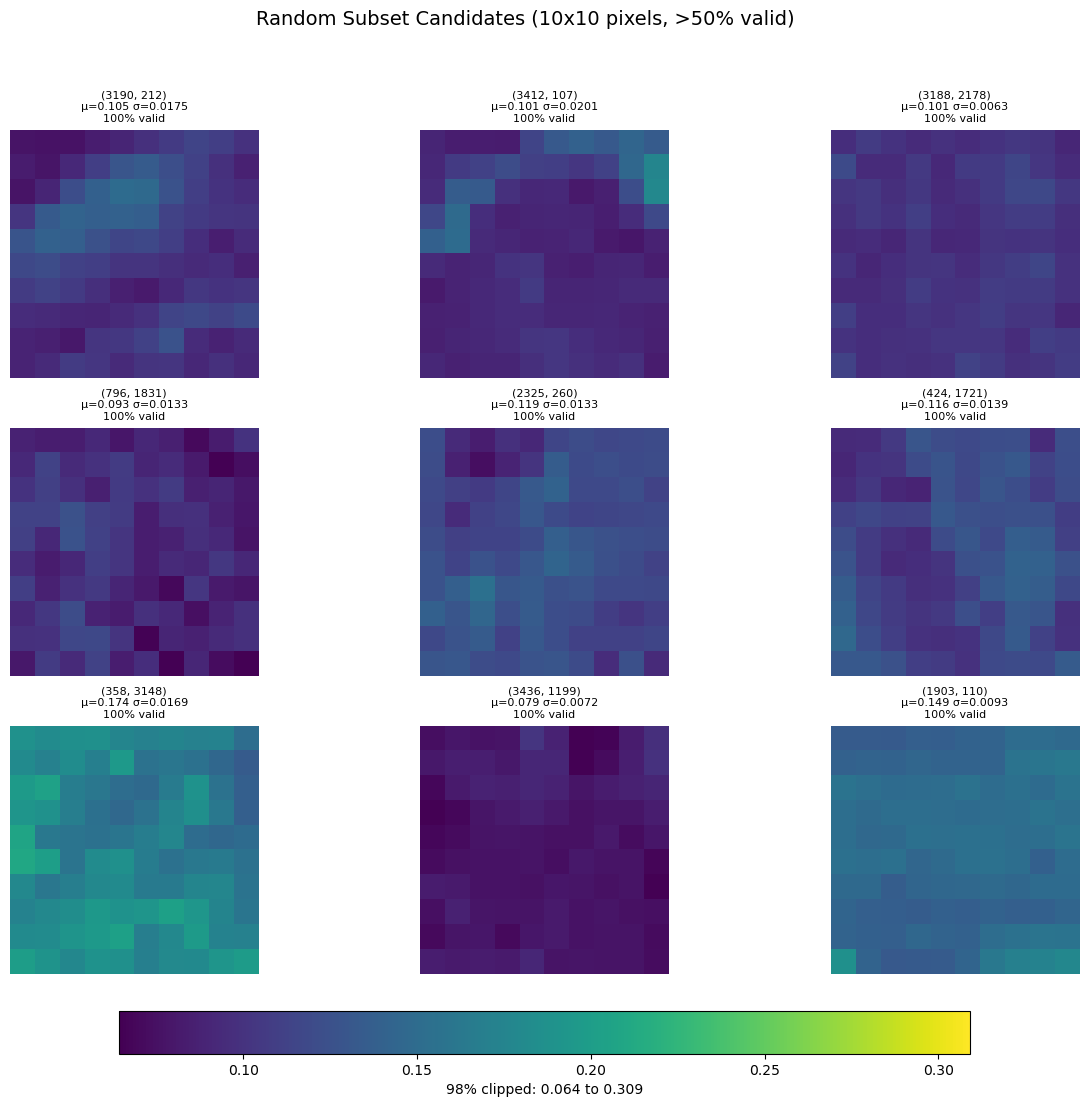


Candidates sorted by homogeneity (>50% valid, lower std = more uniform)
Location             Mean       Std        Valid %   
----------------------------------------------------------------------
(3188, 2178)         0.101      0.0063     100       
(3436, 1199)         0.079      0.0072     100       
(1903, 110)          0.149      0.0093     100       
(796, 1831)          0.093      0.0133     100       
(2325, 260)          0.119      0.0133     100       
(424, 1721)          0.116      0.0139     100       
(358, 3148)          0.174      0.0169     100       
(3190, 212)          0.105      0.0175     100       
(3412, 107)          0.101      0.0201     100       

✓ Most homogeneous: (3188, 2178)

Use: subset_location=(3188, 2178)
Tip: pass seed=<int> to reproduce this exact sampling


In [5]:
location = show_subset_candidates(
    f"{indir}/mean_evi_2025.tif",
    subset_size=(10, 10),
    n_rows=3,
    n_cols=3,
    clip_percentile=98
)